In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_csv("spotify-tracks-dataset.csv")
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 22 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0.1      114000 non-null  int64  
 1   Unnamed: 0        114000 non-null  int64  
 2   track_id          114000 non-null  object 
 3   artists           113999 non-null  object 
 4   album_name        113999 non-null  object 
 5   track_name        113999 non-null  object 
 6   popularity        114000 non-null  int64  
 7   duration_ms       114000 non-null  int64  
 8   explicit          114000 non-null  bool   
 9   danceability      114000 non-null  float64
 10  energy            114000 non-null  float64
 11  key               114000 non-null  int64  
 12  loudness          114000 non-null  float64
 13  mode              114000 non-null  int64  
 14  speechiness       114000 non-null  float64
 15  acousticness      114000 non-null  float64
 16  instrumentalness  11

,Unnamed: 0.1,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [11]:
cols_to_drop = [col for col in ['Unnamed: 0', 'Unnamed: 0.1'] if col in df.columns]
if cols_to_drop:
    df = df.drop(columns=cols_to_drop)

req_cols = ['track_name', 'artists', 'danceability', 'energy',
            'valence', 'acousticness', 'loudness']
df_clean = df[req_cols].copy()

print("\nMissing Values per Column:")
print(df_clean.isnull().sum())

print(f"\nDuplicate Rows: {df_clean.duplicated().sum()}")


Missing Values per Column:
track_name      1
artists         1
danceability    0
energy          0
valence         0
acousticness    0
loudness        0
dtype: int64

Duplicate Rows: 30177


In [12]:
df_clean = df_clean.dropna(subset=['track_name', 'artists'])
df_clean = df_clean.drop_duplicates()

print(f"\nCleaned Dataset Shape: {df_clean.shape}")
print("\nData Types:")
print(df_clean.dtypes)

print("\nAudio Features Summary Statistics:")
display(df_clean.describe())


Cleaned Dataset Shape: (83822, 7)

Data Types:
track_name       object
artists          object
danceability    float64
energy          float64
valence         float64
acousticness    float64
loudness        float64
dtype: object

Audio Features Summary Statistics:


,danceability,energy,valence,acousticness,loudness
count,83822.000000,83822.000000,83822.000000,83822.000000,83822.000000
mean,0.559793,0.635356,0.465137,0.329167,-8.571186
std,0.177127,0.258150,0.263276,0.339639,5.275395
min,0.000000,0.000000,0.000000,0.000000,-49.531000
25%,0.447000,0.456000,0.244000,0.016000,-10.431000
50%,0.573000,0.678000,0.451000,0.189000,-7.251500
75%,0.690000,0.856000,0.678000,0.628000,-5.132000
max,0.985000,1.000000,0.995000,0.996000,4.532000


#Preparing the data

##Removed unnecessary index columns (Unnamed: 0, Unnamed: 0.1):
These were leftover from when the dataset was previously saved to a CSV. Removed since they clutter the DataFrame.

##Keeping relevant columns:
So as to keep workspace focused and prevent scope-creep.

##Removal of missing values:
exactly 1 row missing its track name and artist. restricted the dropna() function to just those identifier columns, removed the corrupted row.

##Removed exact duplicates:
The dataset contained duplicate rows.these duplicates would inflate the frequency of certain tracks, skewing the descriptive statistics.

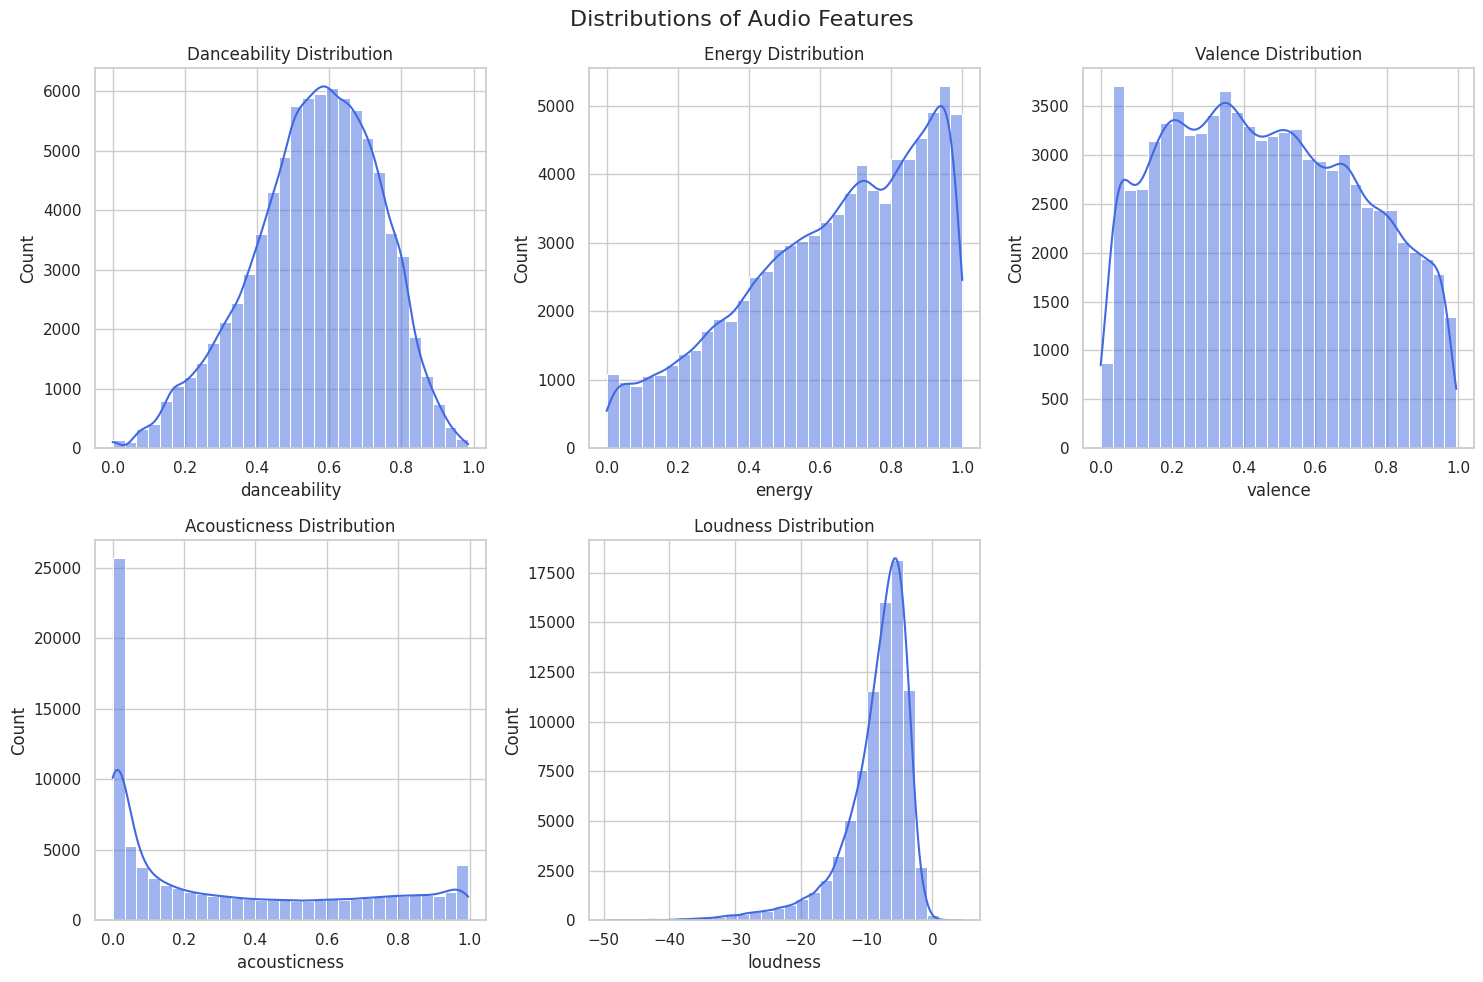

In [18]:
from numpy import fabs
sns.set_theme(style="whitegrid")
features = ['danceability', 'energy', 'valence', 'acousticness', 'loudness']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Distributions of Audio Features', fontsize=16)
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.histplot(df_clean[feature], bins=30, kde=True, ax=axes[i], color='royalblue')
    axes[i].set_title(f'{feature.capitalize()} Distribution')

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

**Danceability**: follows a fairly normal curve, with most tracks sitting around the 0.6 mark.

**energy & loudness**: both lean heavily toward the higher end. energy peaks near 0.8-1.0, while loudness is tightly clustered between -10 and -5 db.

**Valence**: broadly spread out across the board, though it slightly favors the lower to middle ranges.   

**Acousticness:** heavily concentrated right at zero, indicating that the vast majority of the dataset consists of electronically produced or heavily mastered tracks.